In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from helper_files.maoa_plate_loader import *
from helper_files.mea_feats_analysis import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings


warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


In [3]:
#open pickle
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'rb') as file:
    big_df = pickle.load(file)

# fix mislabeled plate files and keep one recording per well per day
big_df = clean_recordings(big_df)

08.22.2025: 12 wells moved MAOA3 -> MAOA2
09.06.2025: 12 wells moved MAOA3 -> MAOA2
09.19.2025: 12 wells moved MAOA2 -> MAOA3
09.19.2025: 12 wells moved MAOA3 -> MAOA2
Dropped 48 duplicate well recordings (kept first recording of the day).


In [4]:
#add experiment group
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]),
    axis=1
)

In [5]:
# Remove bad recording days and detached wells.
# The lists and the reason for each are in helper_files/maoa_plate_loader.py
# (BAD_RECORDING_DATES, EXCLUDED_WELLS); see also README "Data cleaning and exclusions".
big_df = apply_exclusions(big_df)

2025-09-26: removed 36 well recordings (bad recording)
2025-05-09: removed 36 well recordings (noise artefact: every electrode in every well fires ~0.8 Hz (~80x the neighbouring weeks), incl. normally silent KO wells; synchrony ~0)
MAOA76 A4 from 2025-09-25: removed 5 well recordings (GM organoid detached at the Sept re-plating; near-silent (0-5/64 active electrodes))


#### Mutant (c3, c71, c90), WT (c12, c30, c54) and GM

In [6]:
#Remove lines we are not using 
REMOVALS = {
    "MAOA1":{"H9", "C12", "C54","C90"},
    "MAOA2":{"H9", "C12", "C3", "C54","C90"},
    "MAOA3":{"H9", "C12", "C3", "C54","C90"},
    "MAOA72": {"C12", "C90", "C54", },
    "MAOA76": {"C12", "C90", "C54"},
    "MAOA77": {"C12", "C90", "C54"},
}

In [7]:
big_df = remove_clones_by_plate(big_df, REMOVALS)

Removed 402 rows based on plate-specific clone removal.


In [8]:
big_df

,well,firing_rate_stats_hz,burst_rate_stats_hz,network_event_rate_hz,synchrony_index,electrodes,firing_rate_vector_hz,burst_rate_vector_hz,recording_date,recording_date_str,plate_name,cell_line,organoid_age_days,spike_list_path,experiment
0,A2,"[1.4391208230357608, 1.6648439676442284]","[0.09436092897565711, 0.09586305971365496]",0.124031,0.022132,"[A2_11, A2_12, A2_13, A2_14, A2_15, A2_16, A2_...","[3.015680429868851, 0.0006597419448411399, 0.0...","[0.19066542205908946, nan, nan, nan, 0.0032987...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
1,A3,"[0.4052027312243695, 0.5762036681376207]","[0.018160265113258748, 0.024168885783248578]",0.003299,0.000282,"[A3_11, A3_12, A3_13, A3_14, A3_15, A3_16, A3_...","[nan, 0.0006597419448411399, 0.000659741944841...","[nan, nan, nan, nan, 0.00791690333809368, nan,...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
2,B1,"[2.0029325617413787, 2.347922067937726]","[0.1179549150855449, 0.11597167105563749]",0.032327,0.007995,"[B1_11, B1_12, B1_13, B1_14, B1_15, B1_16, B1_...","[2.4403854539673766, 0.0006597419448411399, 3....","[0.07653006560157223, nan, 0.16889393787933182...",2025-04-14,04.14.2025,MAOA2,C71,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
3,B2,"[1.821286102520696, 3.2362072623431377]","[0.1274676415928486, 0.11408226907420285]",0.148442,0.013659,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.0013194838896822799, 3.5289596629552578, 0....","[nan, 0.20188103512138883, nan, nan, 0.0936833...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
4,B3,"[0.7793130012355004, 1.3467926472630483]","[0.058214372561458665, 0.07832226183330862]",0.078509,0.001454,"[B3_11, B3_12, B3_13, B3_14, B3_15, B3_16, B3_...","[5.249566655100951, 0.0006597419448411399, nan...","[0.17747058316226666, nan, nan, 0.085106710884...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
956,A2,"[0.2001678022716308, 0.40852412447408004]","[0.03624468325620345, 0.03070101746160311]",0.008220,0.098530,"[A2_11, A2_12, A2_13, A2_14, A2_15, A2_16, A2_...","[nan, 0.0016440887250236617, 0.000822044362511...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,C71,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
957,B1,"[0.26199502345978026, 0.7419211332715153]","[0.02757010323501217, 0.025920461645713547]",0.000000,0.046000,"[B1_11, B1_12, B1_13, B1_14, B1_15, B1_16, B1_...","[nan, 0.0008220443625118308, 0.002466133087535...","[nan, nan, nan, nan, 0.01808497597526028, nan,...",2025-10-30,10.30.2025,MAOA76,C3,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
958,B2,"[0.4753718139533415, 1.490921272006652]","[0.03565617422395066, 0.04528512776359013]",0.000000,0.037999,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.024661330875354926, 0.17920567102757912, 0....","[nan, 0.007398399262606477, 0.0024661330875354...",2025-10-30,10.30.2025,MAOA76,C71,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
959,B4,"[0.010609510053668317, 0.045617147944364]","[0.01808497597526028, 0.0]",0.000000,-0.001633,"[B4_11, B4_12, B4_13, B4_14, B4_15, B4_16, B4_...","[0.004932266175070985, 0.0008220443625118308, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3


### Exp 3 analysis for Paper Figure

In [9]:
# Updated palette using the specific genetic strings as keys
MAOA_FIGURE_PALETTE = {
    "Xa:WT/Xi:MUT": "#9C899C", 
    "Xa:MUT/Xi:WT": "#EAC3EB", 
    "MAOA/B$^{-/Y}$": "#E980C0"  # Note the $ and ^
}

PLOT_ORDER = ["Xa:WT/Xi:MUT", "Xa:MUT/Xi:WT", "MAOA/B$^{-/Y}$"]



FEATURE: FIRING


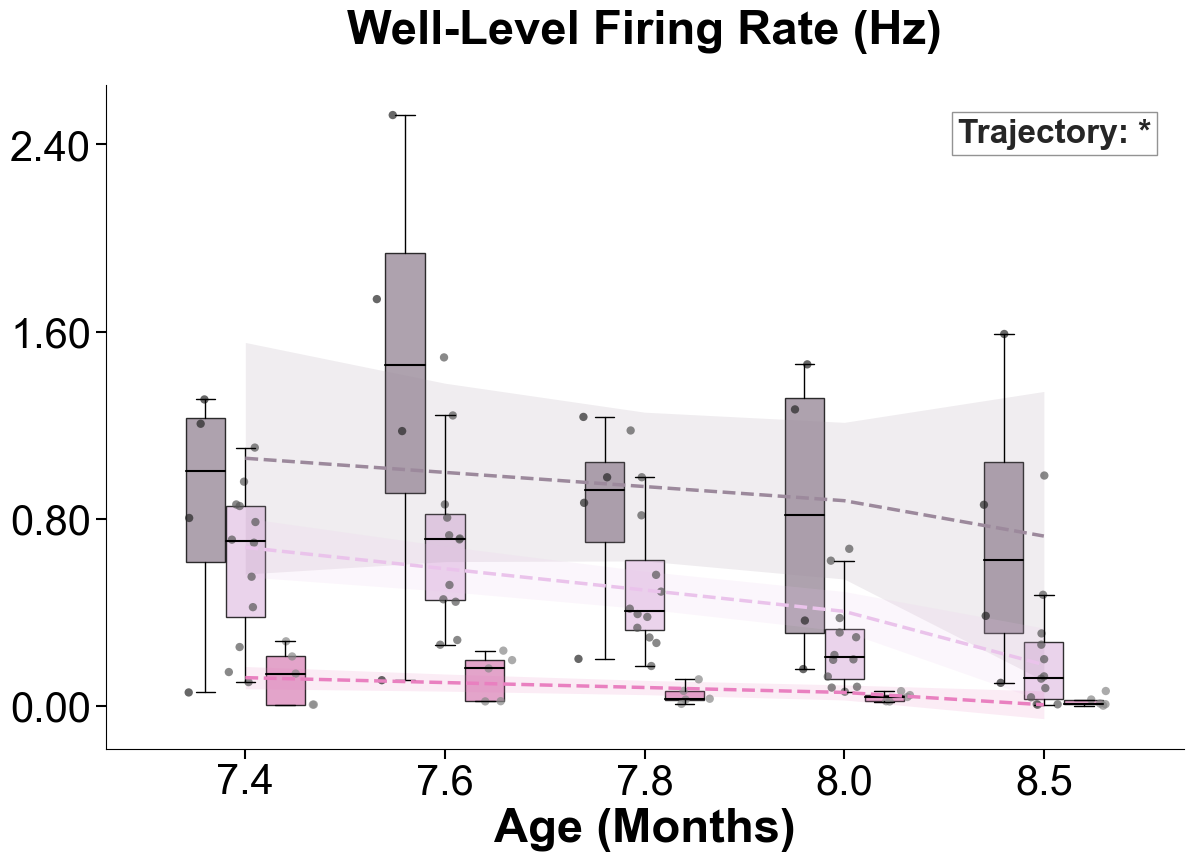

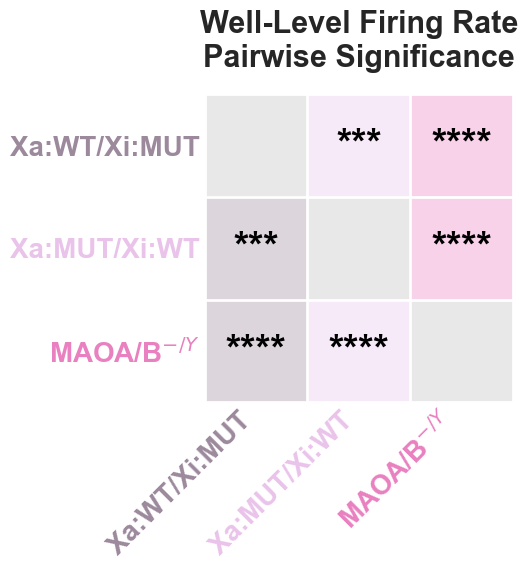

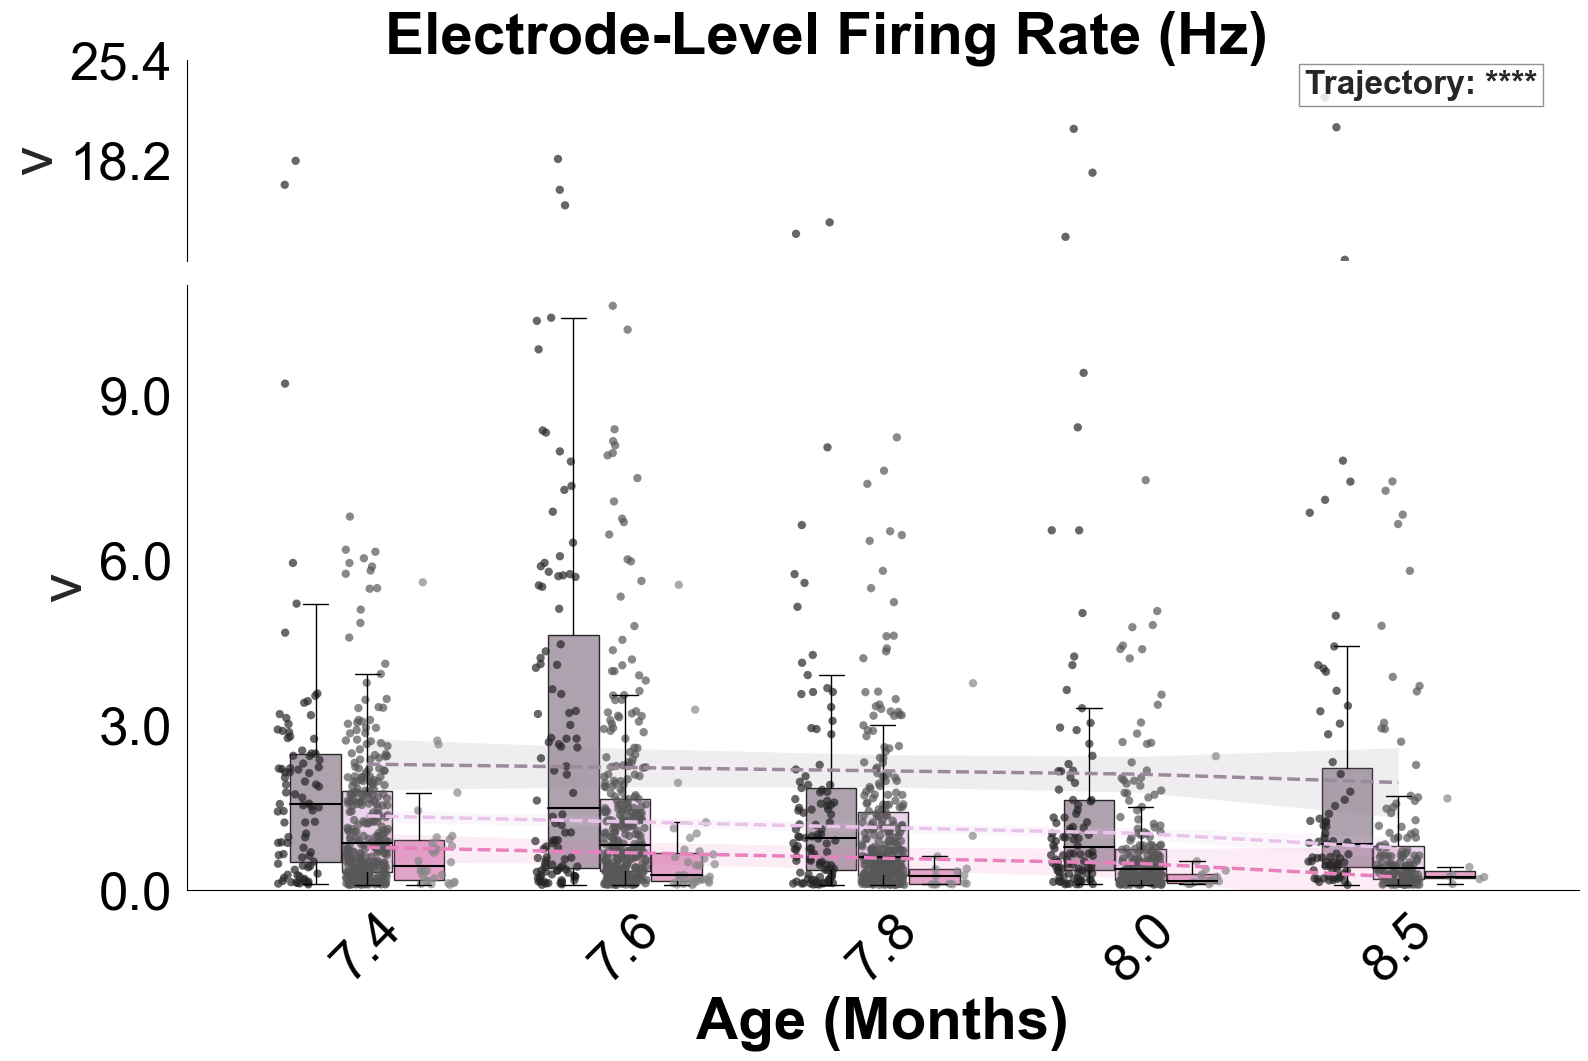

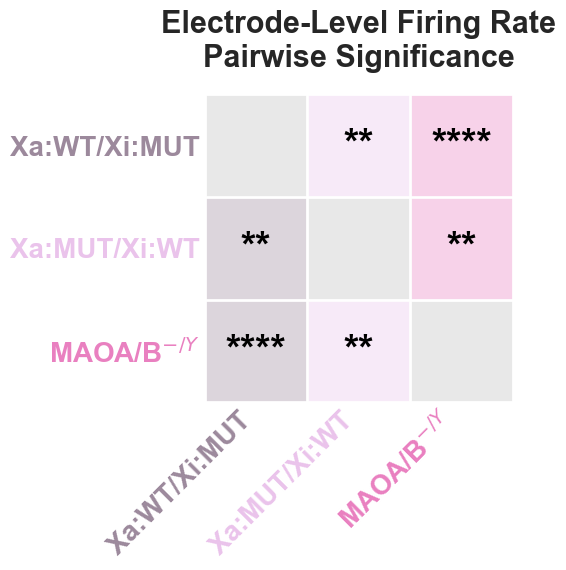


--- WELL-LEVEL FIRING: mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 8.71e-07 ****
        age 2.04e-12 ****
group x age   0.0172    *
Overall group differences (Holm):
        group1       group2  diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.367 2.36e-08 ****
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.599  4.2e-13 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.232 0.000914  ***
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                           ****                           ****                           ns
  7.6                           ****                           ****                            *
  7.8                           ****                           ****                           ns
  8.0                              *                           ****                           **
  8.5                              *      

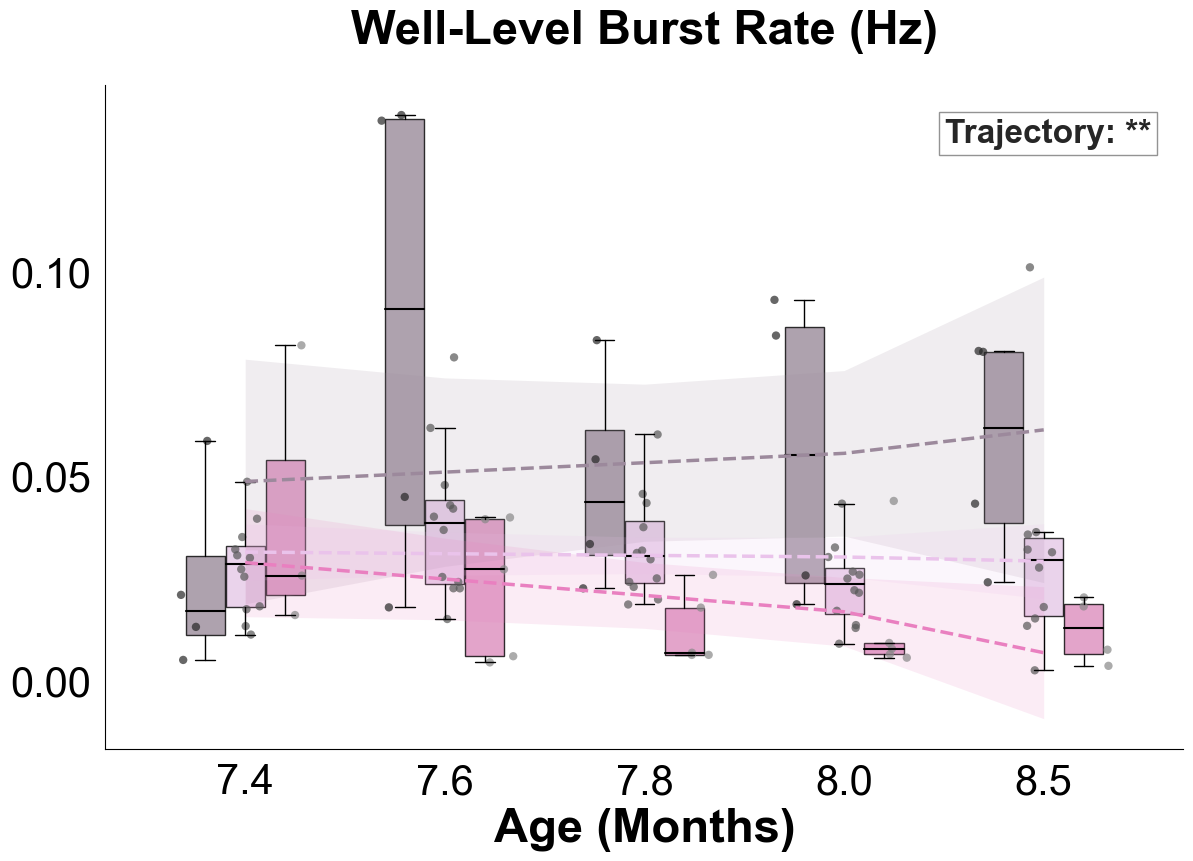

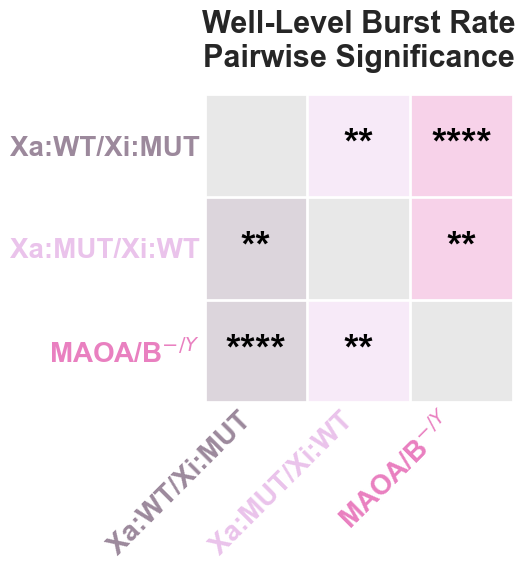

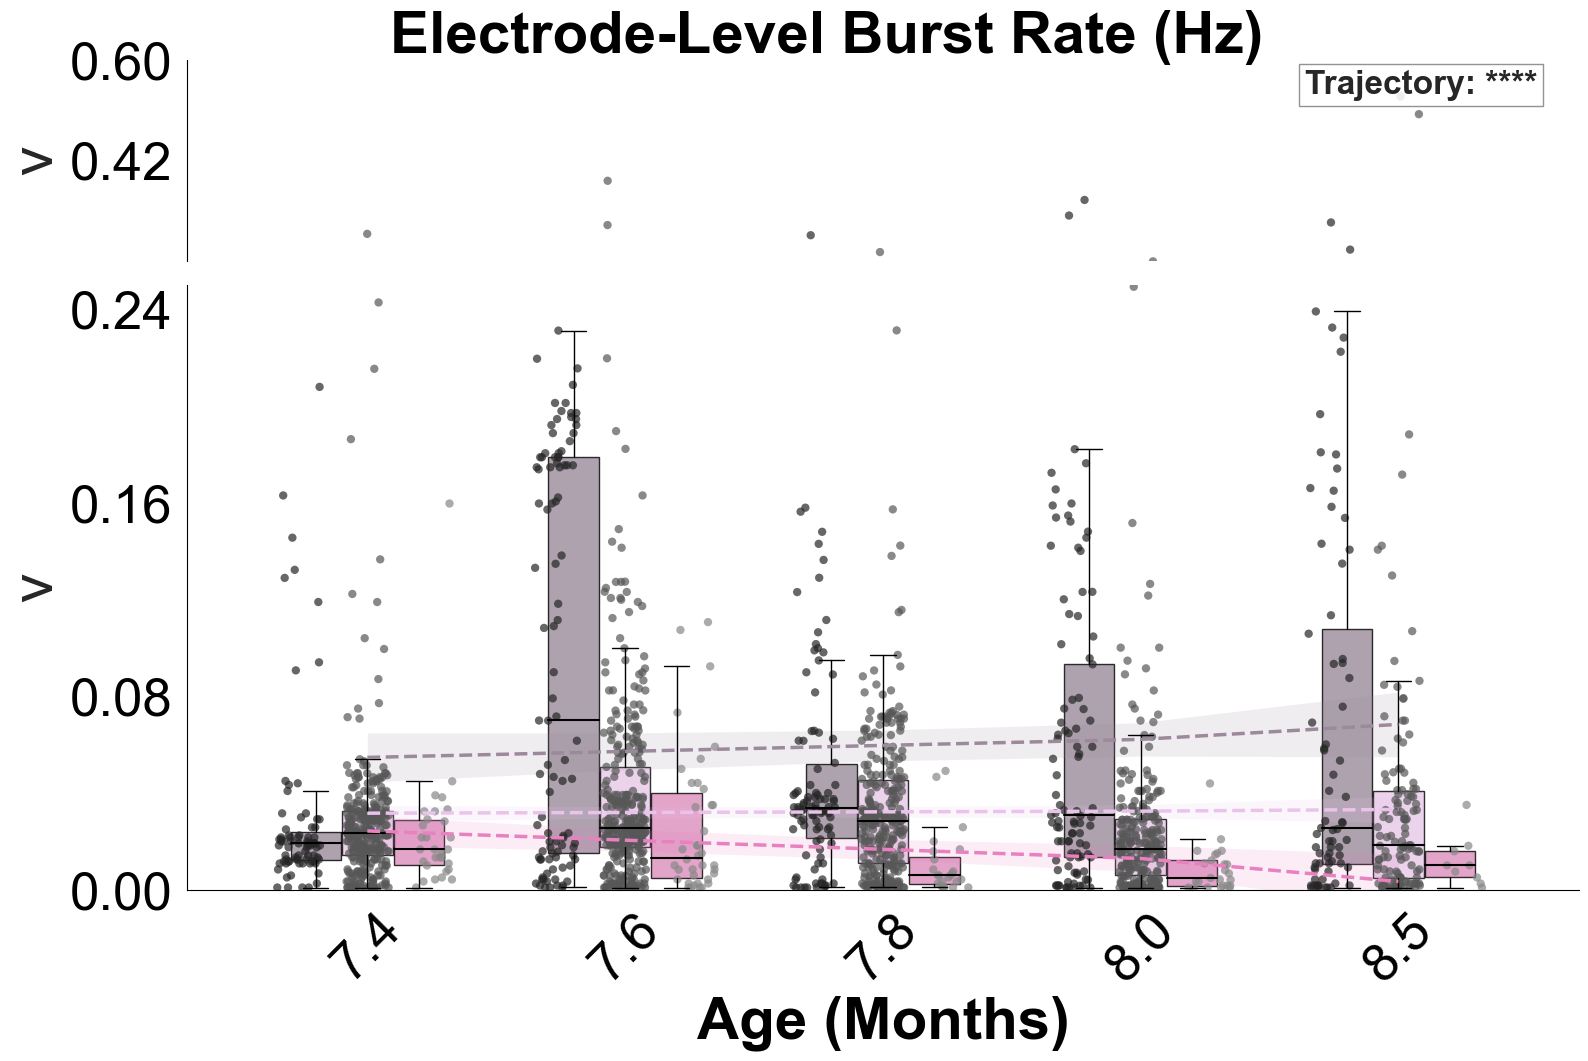

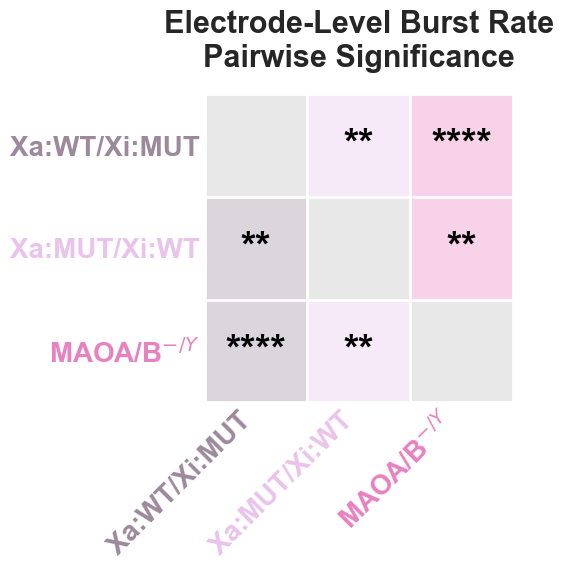


--- WELL-LEVEL BURST: mixed model, random intercept per well (n=100, wells=21) ---
       term        p  sig
      group 7.01e-05 ****
        age   0.0129    *
group x age  0.00317   **
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0409  0.00137   **
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.0873 9.23e-08 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0464  0.00105   **
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                             ns                           ****                           **
  7.8                              *                             **                           ns
  8.0                             ns                             **                            *
  8.5                             ns   

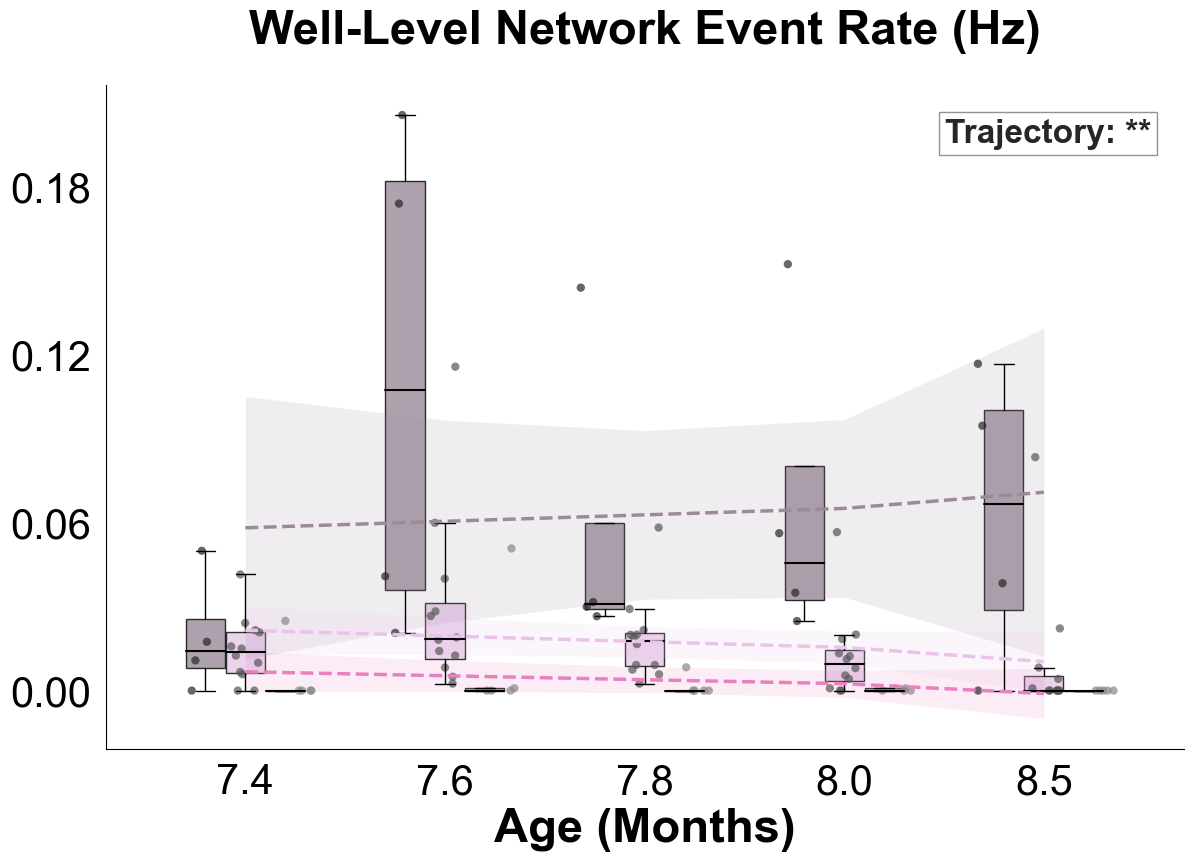

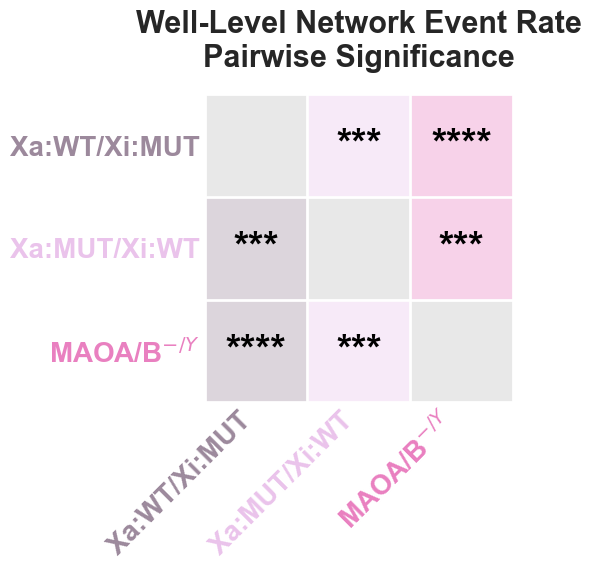


--- WELL-LEVEL NETWORK: mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 3.68e-05 ****
        age 7.97e-05 ****
group x age   0.0095   **
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0837 0.000935  ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.187 1.26e-08 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT  0.103 0.000341  ***
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                              *                           ****                           **
  7.8                              *                            ***                           ns
  8.0                             ns                           ****                           **
  8.5                             ns 

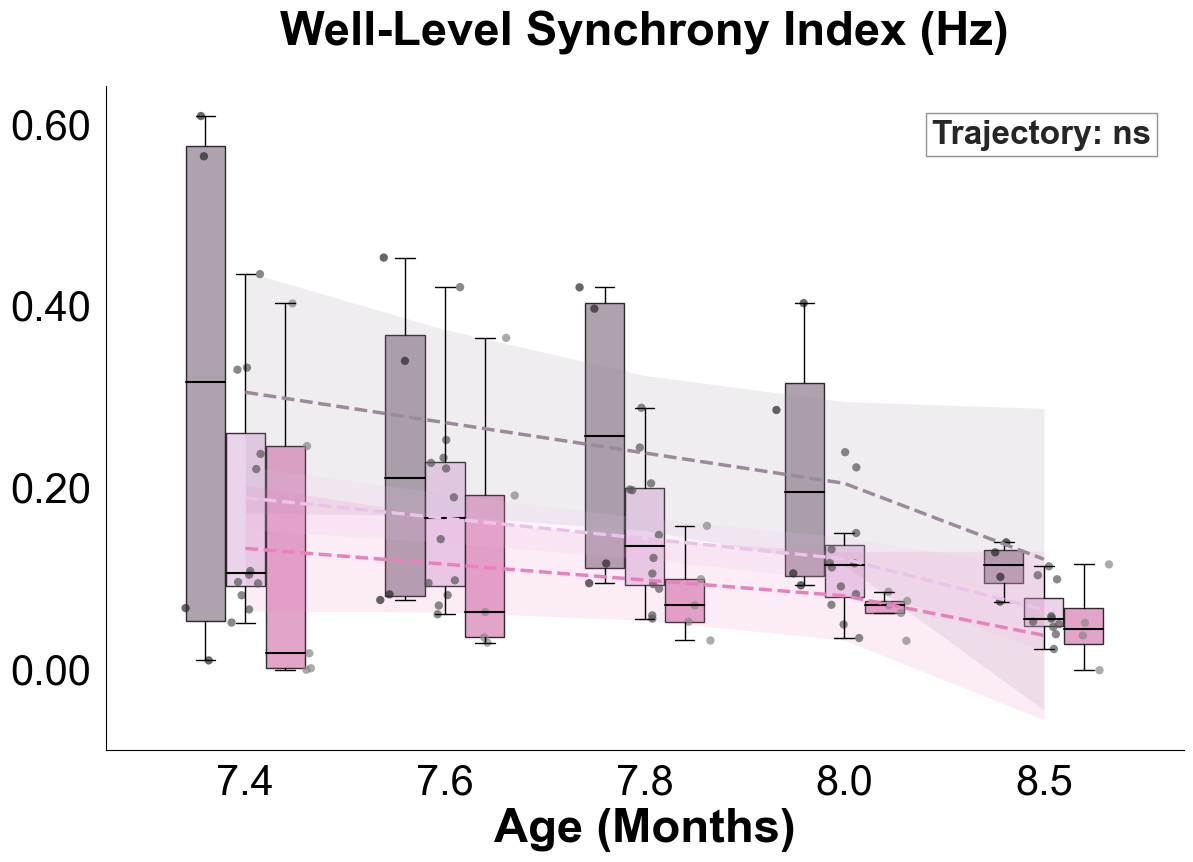

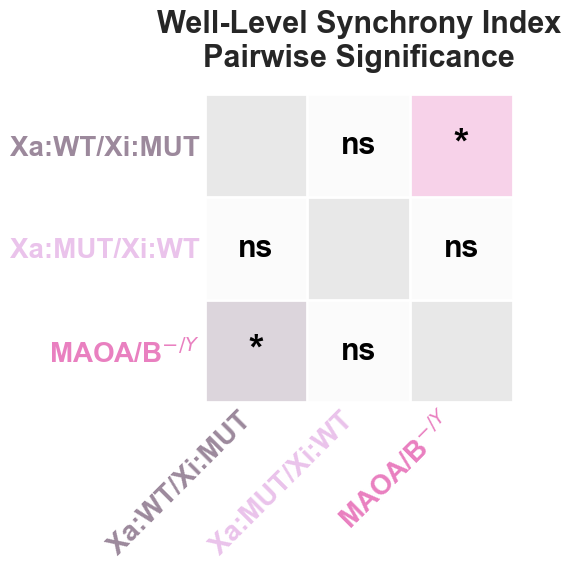


--- WELL-LEVEL SYNCHRONY: mixed model, random intercept per well (n=103, wells=21) ---
       term        p  sig
      group   0.0466    *
        age 9.83e-06 ****
group x age    0.843   ns
Overall group differences (Holm):
        group1       group2   diff  p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0592  0.172  ns
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.133 0.0229   *
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0737  0.172  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                             ns                             ns                           ns
  7.8                             ns                             ns                           ns
  8.0                             ns                             ns                           ns
  8.5                             ns           

In [10]:
import importlib
import helper_files.mea_feats_analysis as _m
importlib.reload(_m)
from helper_files.mea_feats_analysis import run_mea_analysis_for_figure

SAVE_DIR = "/Users/blancamartin/Desktop/Muotri_lab/MAOA_project/figures"

my_stats = run_mea_analysis_for_figure(
    big_df,
    experiment='Exp3', unit="months",
    palette=MAOA_FIGURE_PALETTE,
    save_dir=SAVE_DIR
)


--- GENERATING GROUPED PLOTS FOR FIRING ---


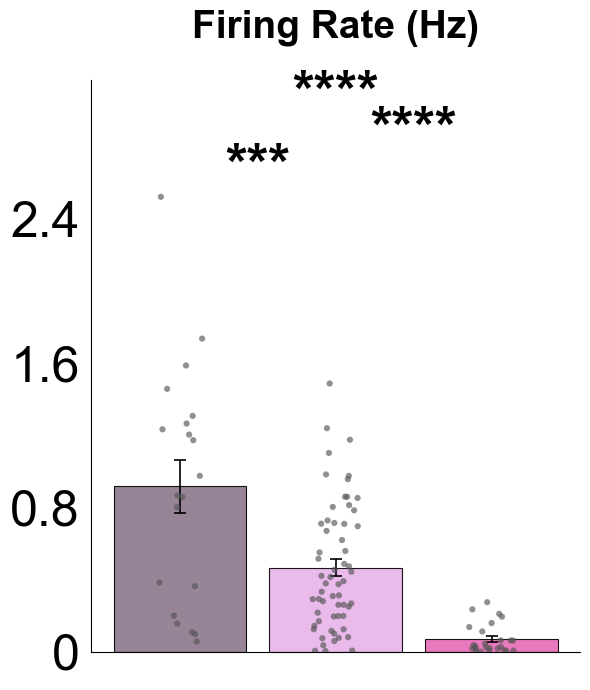

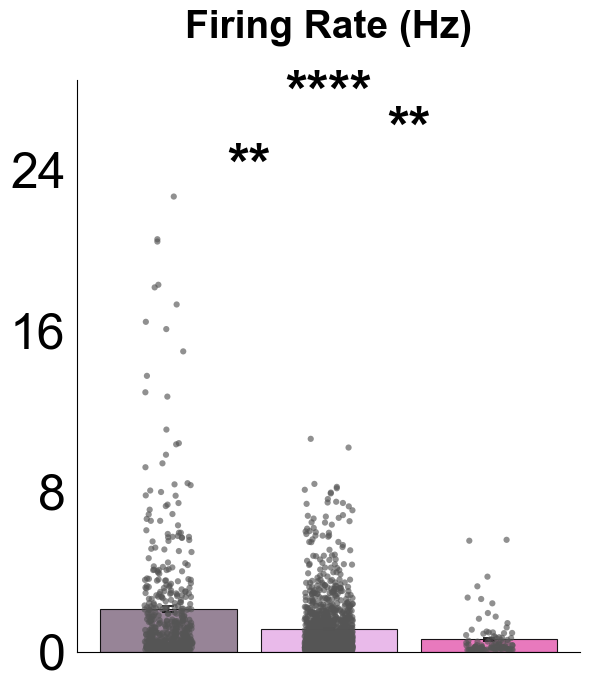


--- WELL-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 8.71e-07 ****
        age 2.04e-12 ****
group x age   0.0172    *
Overall group differences (Holm):
        group1       group2  diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.367 2.36e-08 ****
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.599  4.2e-13 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.232 0.000914  ***
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                           ****                           ****                           ns
  7.6                           ****                           ****                            *
  7.8                           ****                           ****                           ns
  8.0                              *                           ****                           **
  8.5                          

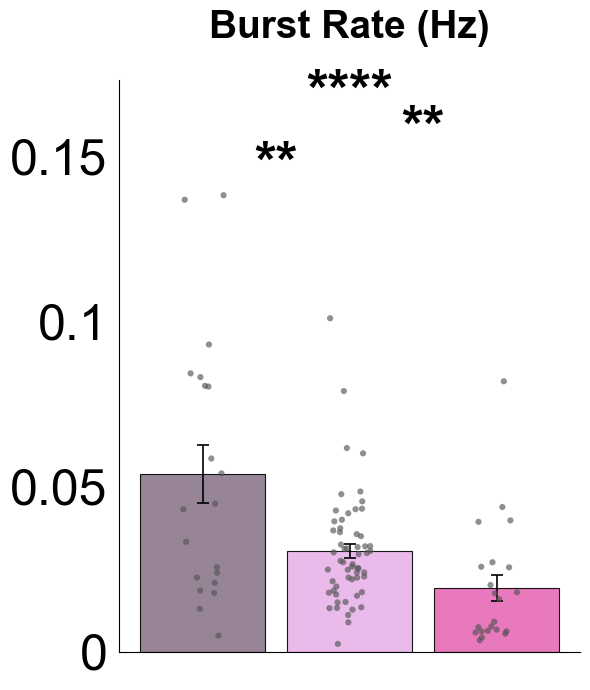

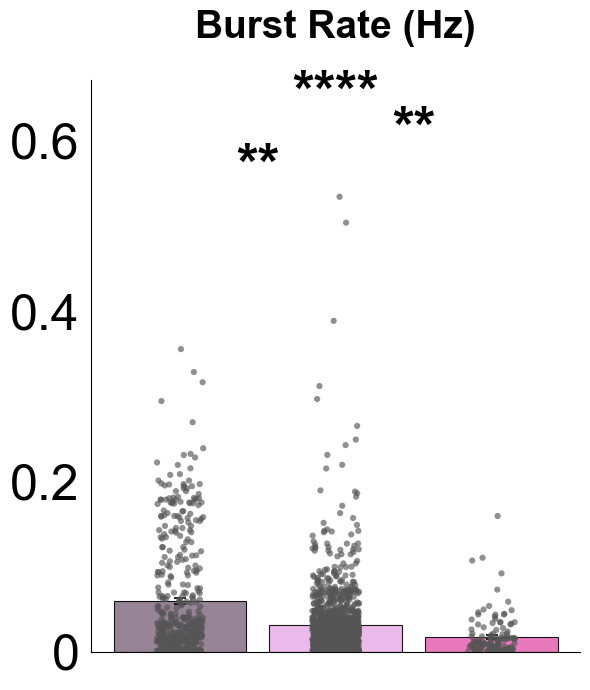


--- WELL-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=100, wells=21) ---
       term        p  sig
      group 7.01e-05 ****
        age   0.0129    *
group x age  0.00317   **
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0409  0.00137   **
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.0873 9.23e-08 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0464  0.00105   **
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                             ns                           ****                           **
  7.8                              *                             **                           ns
  8.0                             ns                             **                            *
  8.5                       

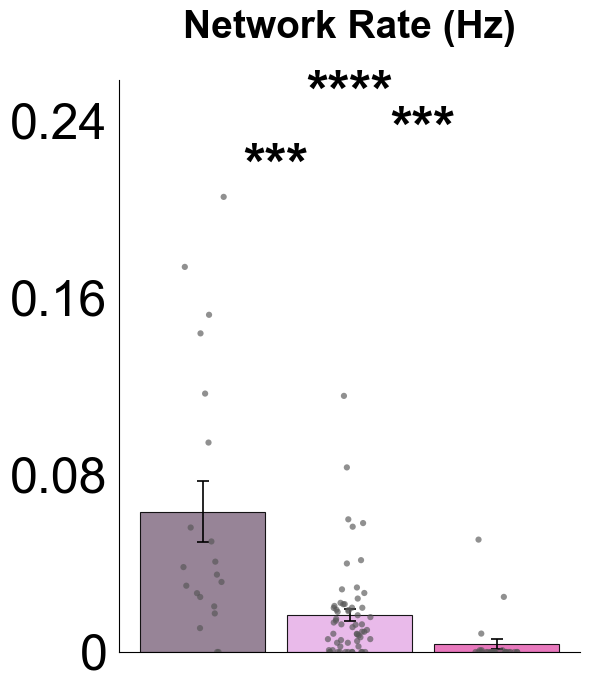


--- WELL-LEVEL NETWORK (BAR PLOT): mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 3.68e-05 ****
        age 7.97e-05 ****
group x age   0.0095   **
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0837 0.000935  ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.187 1.26e-08 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT  0.103 0.000341  ***
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                              *                           ****                           **
  7.8                              *                            ***                           ns
  8.0                             ns                           ****                           **
  8.5                     

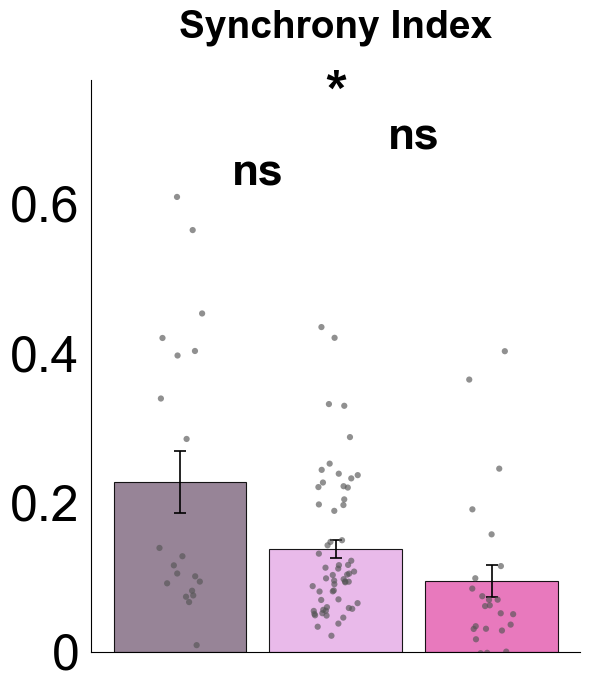


--- WELL-LEVEL SYNCHRONY (BAR PLOT): mixed model, random intercept per well (n=103, wells=21) ---
       term        p  sig
      group   0.0466    *
        age 9.83e-06 ****
group x age    0.843   ns
Overall group differences (Holm):
        group1       group2   diff  p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0592  0.172  ns
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.133 0.0229   *
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0737  0.172  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                             ns                             ns                           ns
  7.8                             ns                             ns                           ns
  8.0                             ns                             ns                           ns
  8.5                             ns

In [11]:
import importlib
import helper_files.mea_feats_analysis as _m
importlib.reload(_m)
from helper_files.mea_feats_analysis import run_grouped_analysis

run_grouped_analysis(big_df, "Exp3", save_dir=SAVE_DIR)

# Supplementary Figures — Activity by Clone

In [12]:
import importlib
import helper_files.mea_feats_analysis as _m
importlib.reload(_m)
from helper_files.mea_feats_analysis import run_mea_analysis_by_clone, run_grouped_analysis_by_clone

SUPP_SAVE_DIR = "/Users/blancamartin/Desktop/Muotri_lab/MAOA_project/figures/supplementary"


FEATURE: FIRING


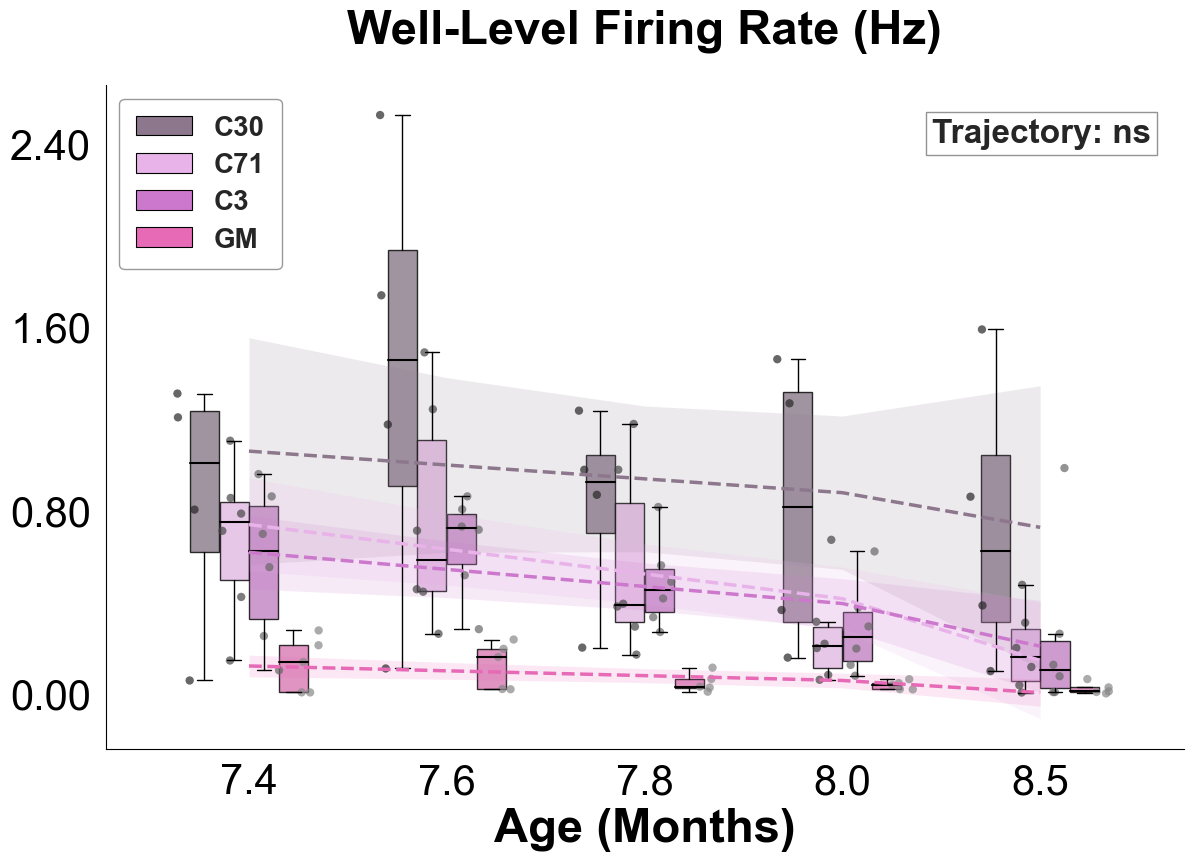

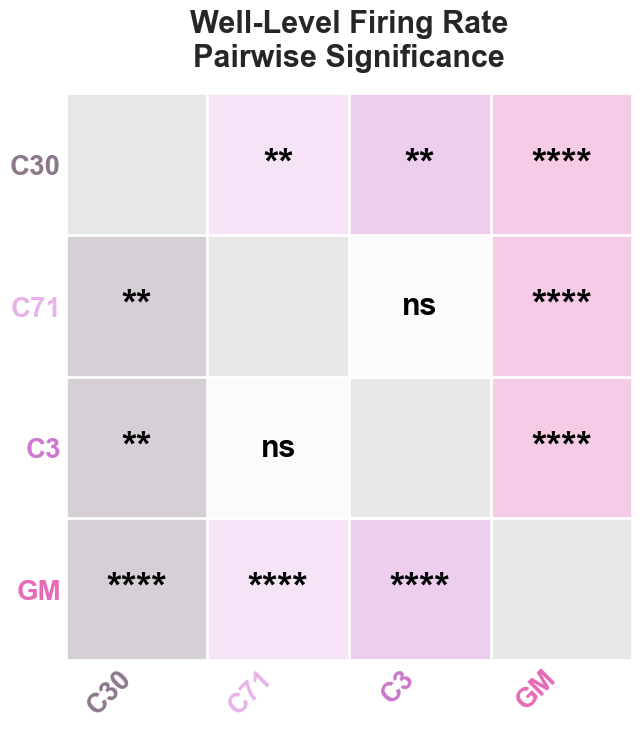

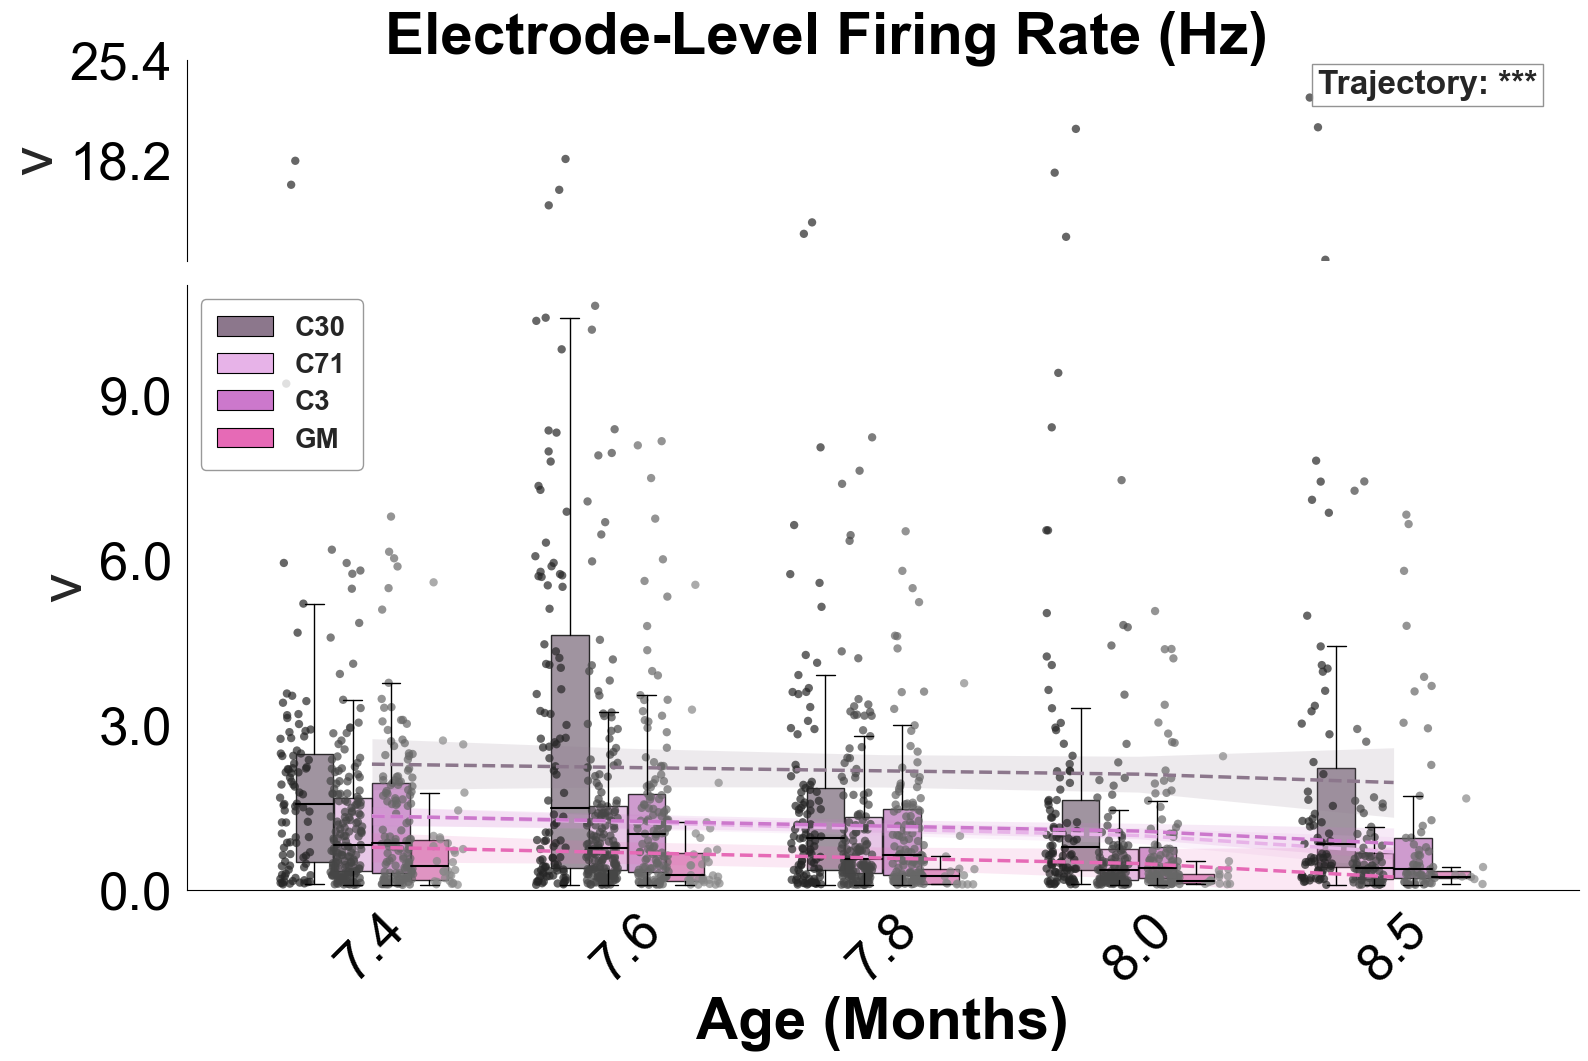

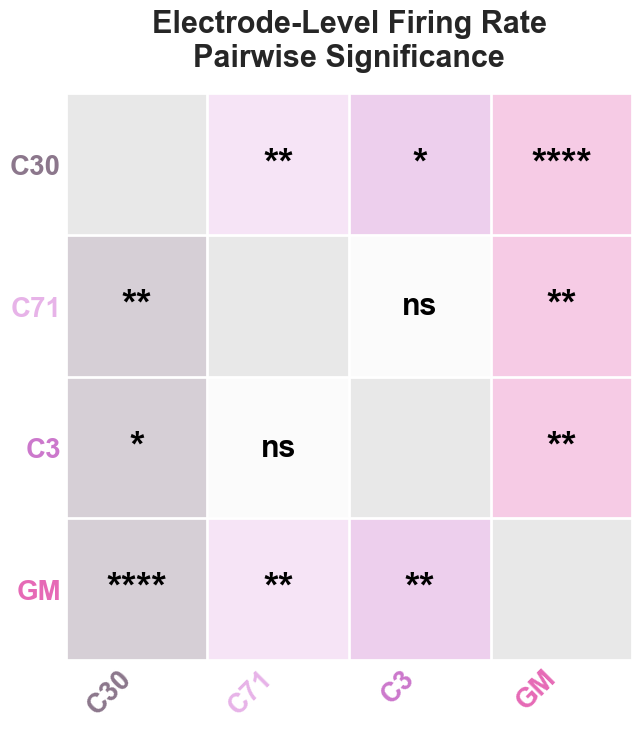


--- WELL-LEVEL FIRING: mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 3.61e-06 ****
        age 2.04e-12 ****
group x age   0.0691   ns
Overall group differences (Holm):
group1 group2   diff    p-adj  sig
    C3    C30  0.243  0.00543   **
    C3    C71 0.0221    0.749   ns
    C3     GM -0.356  4.2e-06 ****
   C30    C71 -0.221  0.00914   **
   C30     GM -0.599 7.33e-13 ****
   C71     GM -0.379 1.08e-06 ****
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       **         ns       ***      ****
  7.6        ns        ns      ***         ns      ****      ****
  7.8        ns        ns      ***         ns      ****      ****
  8.0        ns        ns       ns          *      ****        ns
  8.5        **        ns       ns         **      ****        ns

--- ELECTRODE-LEVEL FIRING: mixed model, random intercept per well + per elec

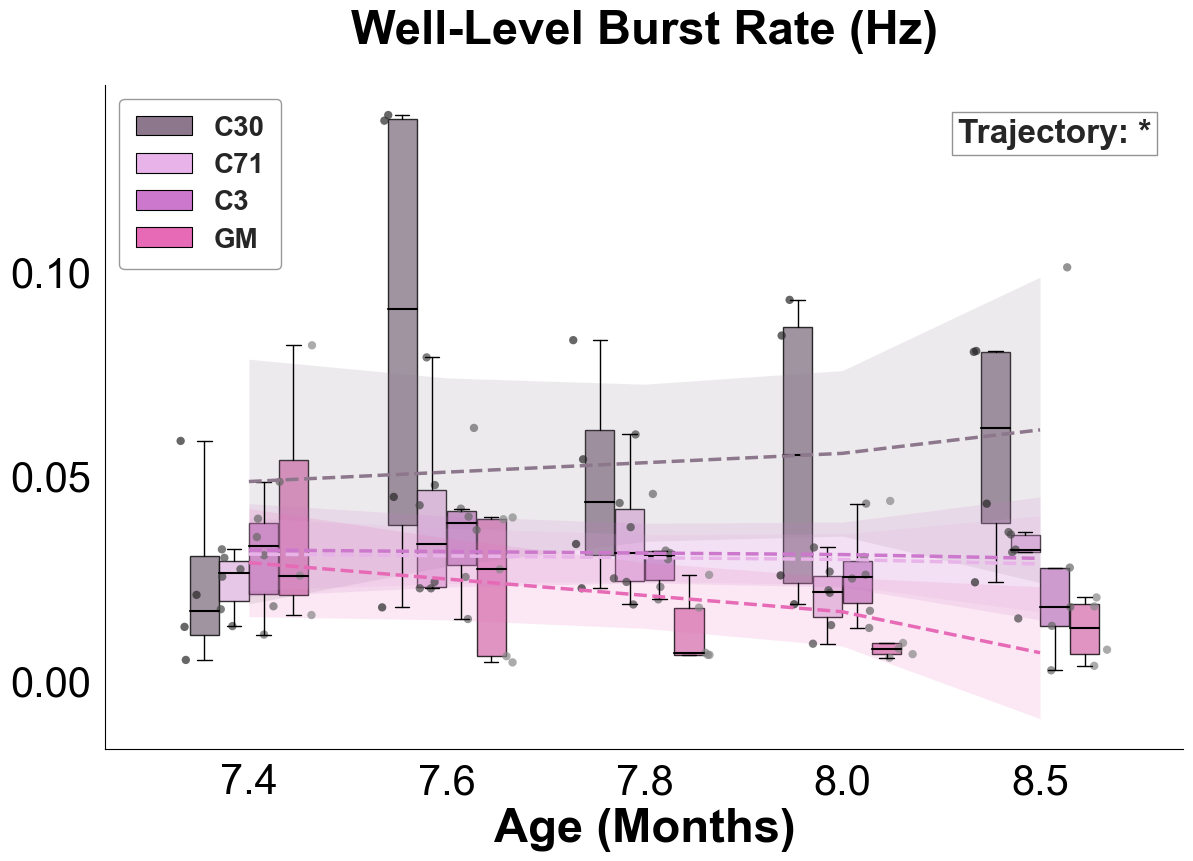

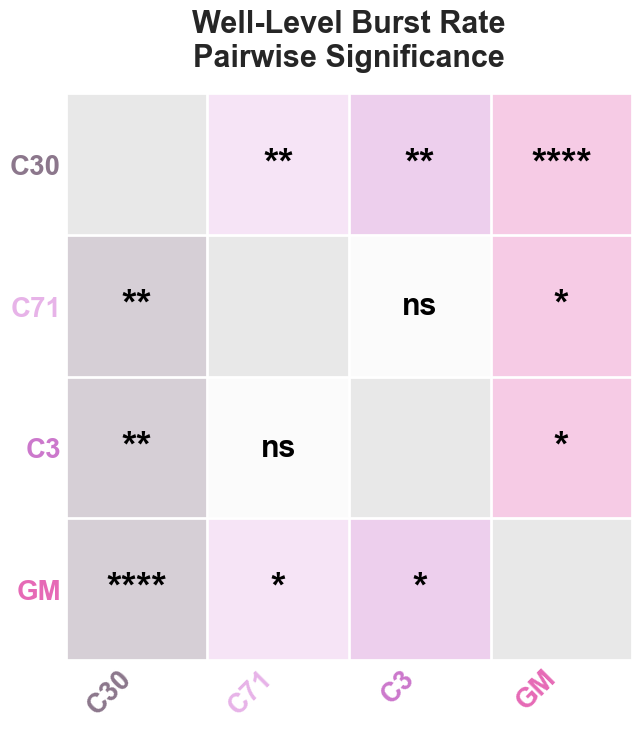

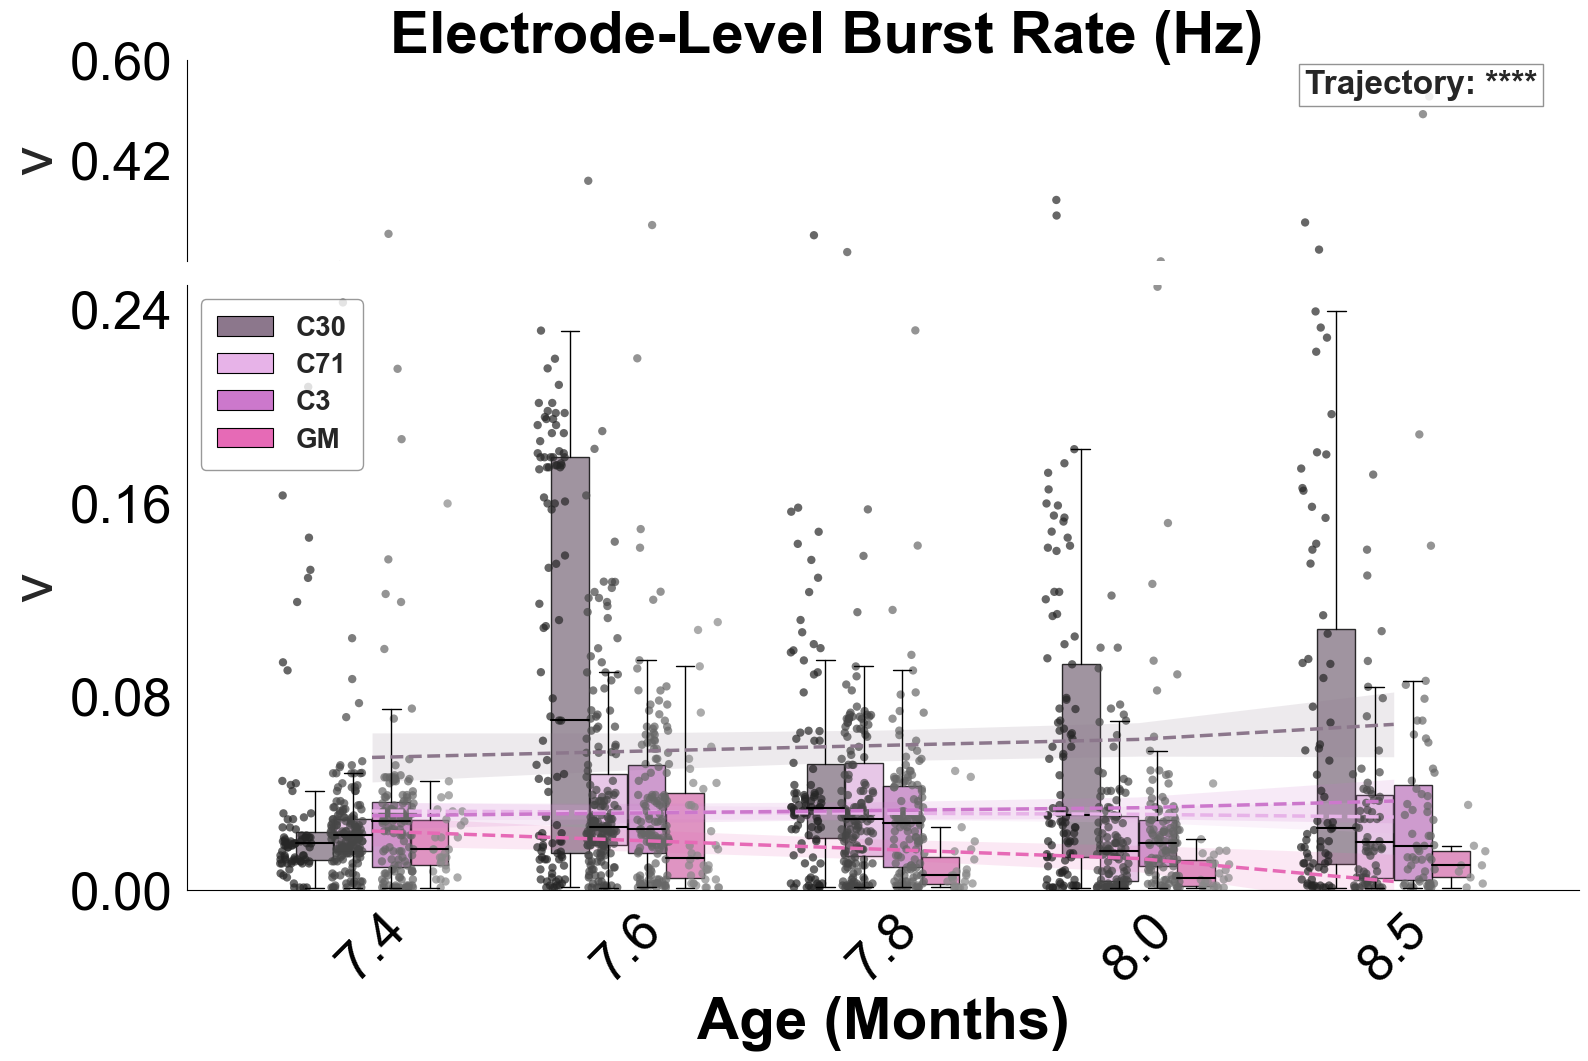

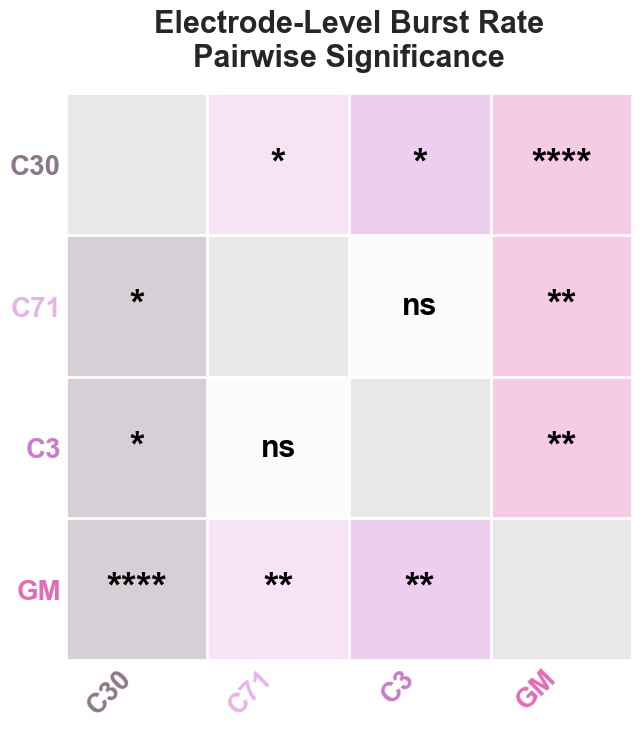


--- WELL-LEVEL BURST: mixed model, random intercept per well (n=100, wells=21) ---
       term        p sig
      group 0.000256 ***
        age   0.0129   *
group x age   0.0149   *
Overall group differences (Holm):
group1 group2      diff    p-adj  sig
    C3    C30     0.046  0.00876   **
    C3    C71 -0.000864    0.949   ns
    C3     GM   -0.0413   0.0125    *
   C30    C71   -0.0468  0.00876   **
   C30     GM   -0.0873 1.85e-07 ****
   C71     GM   -0.0405   0.0125    *
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6         *        ns       ns         ns       ***        ns
  7.8        ns        ns       ns         ns        **        ns
  8.0        ns        ns       ns         ns        **        ns
  8.5        ns        ns       ns         ns       ***        ns

--- ELECTRODE-LEVEL BURST: mixed model, random intercept per 

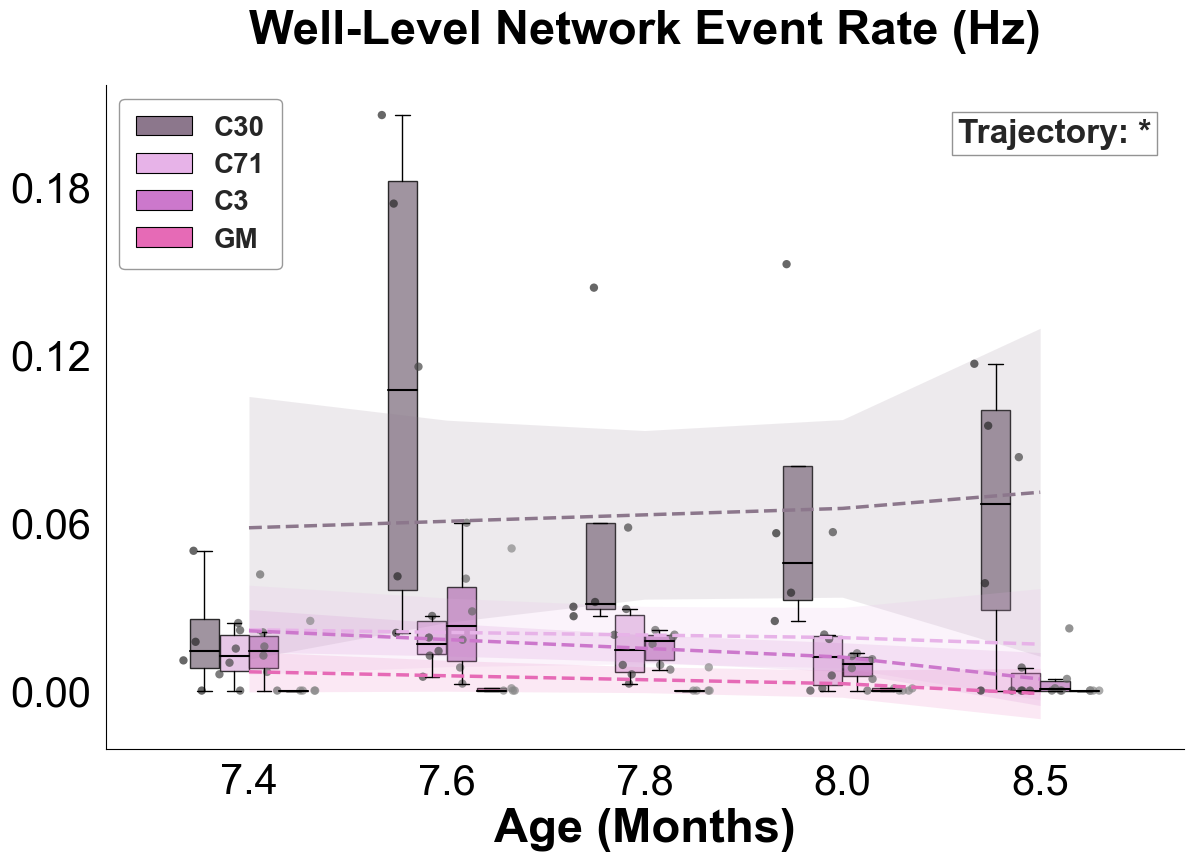

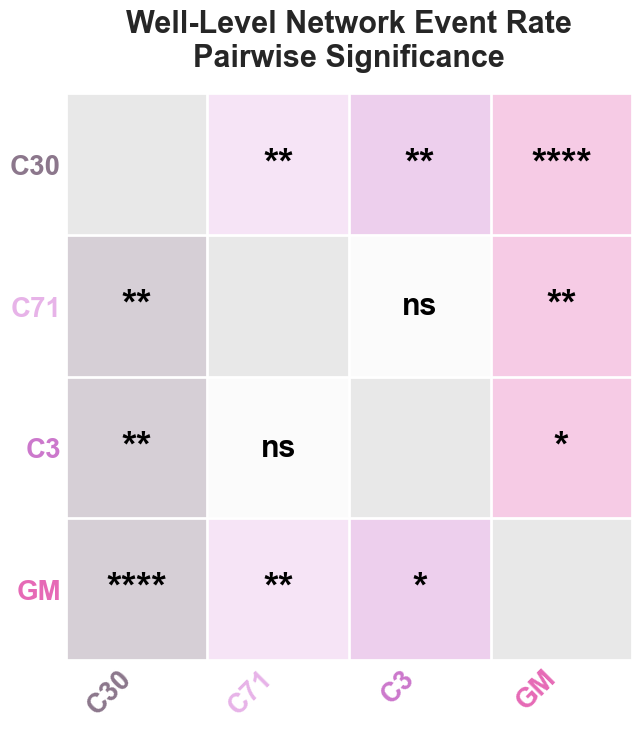


--- WELL-LEVEL NETWORK: mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 0.000131  ***
        age 7.97e-05 ****
group x age   0.0487    *
Overall group differences (Holm):
group1 group2    diff    p-adj  sig
    C3    C30   0.108  0.00201   **
    C3    C71 0.00977    0.719   ns
    C3     GM -0.0788   0.0118    *
   C30    C71 -0.0983  0.00515   **
   C30     GM  -0.187 2.26e-08 ****
   C71     GM -0.0886  0.00593   **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6         *        ns       ns          *      ****        ns
  7.8        ns        ns       ns         ns       ***        ns
  8.0        **        ns       ns          *      ****        ns
  8.5        **        ns       ns          *       ***        ns

FEATURE: SYNCHRONY


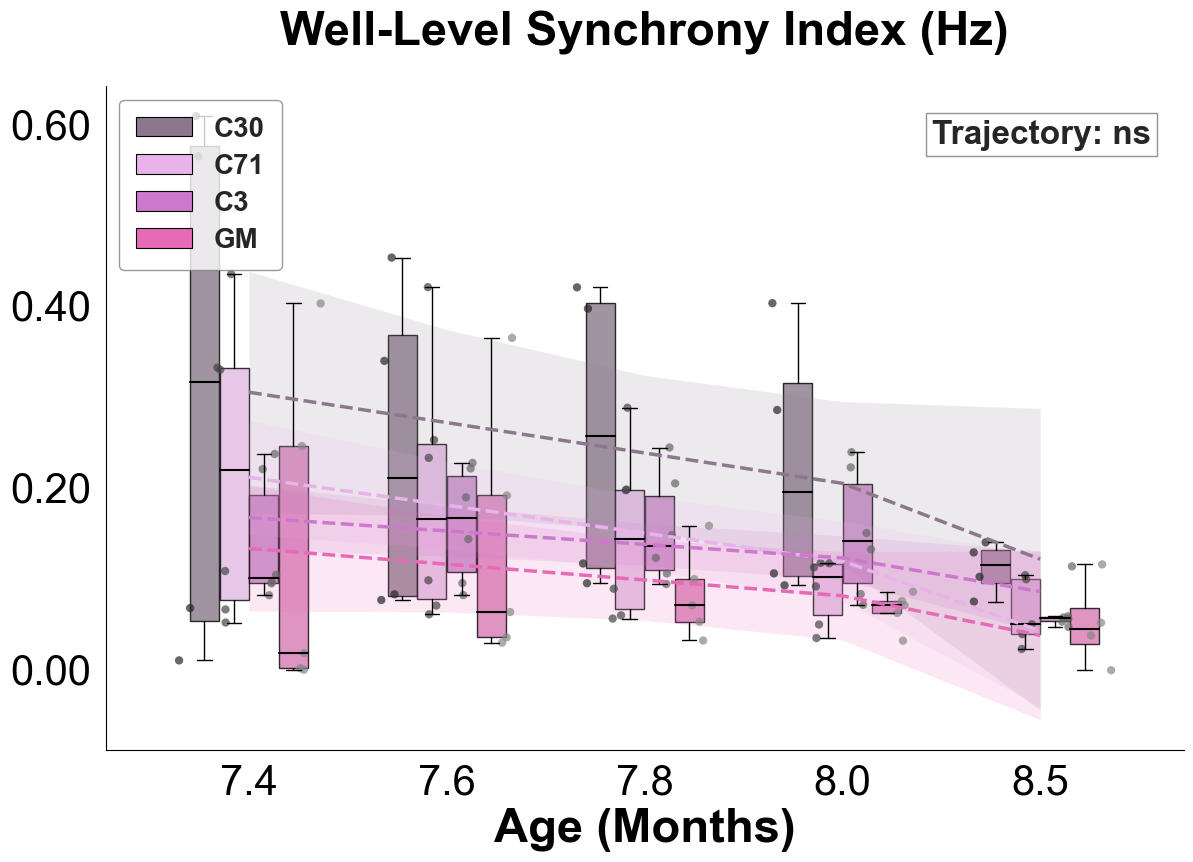


--- WELL-LEVEL SYNCHRONY: mixed model, random intercept per well (n=103, wells=21) ---
       term        p  sig
      group    0.102   ns
        age 9.99e-06 ****
group x age     0.56   ns
Overall group differences (Holm):
group1 group2    diff  p-adj sig
    C3    C30  0.0795  0.484  ns
    C3    C71  0.0116  0.786  ns
    C3     GM -0.0535  0.595  ns
   C30    C71 -0.0679  0.595  ns
   C30     GM  -0.133 0.0453   *
   C71     GM -0.0651  0.595  ns
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6        ns        ns       ns         ns        ns        ns
  7.8        ns        ns       ns         ns        ns        ns
  8.0        ns        ns       ns         ns        ns        ns
  8.5        ns        ns       ns         ns        ns        ns


{'firing': {'Well-Level': {'data':     group  time_val plate_name    well_id       val         y
   0      C3       7.4     MAOA72  MAOA72_A1  0.958778  0.979172
   1     C71       7.4     MAOA72  MAOA72_A2  1.104464  1.050935
   2      GM       7.4     MAOA72  MAOA72_A4  0.211839  0.460260
   3      C3       7.4     MAOA72  MAOA72_B1  0.697875  0.835389
   4     C71       7.4     MAOA72  MAOA72_B2  0.786325  0.886749
   ..    ...       ...        ...        ...       ...       ...
   100   C71       8.5     MAOA76  MAOA76_A2  0.200168  0.447401
   101    C3       8.5     MAOA76  MAOA76_B1  0.261995  0.511854
   102   C71       8.5     MAOA76  MAOA76_B2  0.475372  0.689472
   103    GM       8.5     MAOA76  MAOA76_B4  0.010610  0.103002
   104   C30       8.5     MAOA76  MAOA76_C2  1.589935  1.260926
   
   [105 rows x 6 columns],
   'lrt':           term             p
   0        group  3.614164e-06
   1          age  2.042820e-12
   2  group x age  6.905010e-02,
   'overall':   group

In [13]:
# Trajectory plots by clone (replaces run_mea_analysis_for_figure)
run_mea_analysis_by_clone(big_df, experiment="Exp3", unit="months", save_dir=SUPP_SAVE_DIR)


--- GENERATING CLONE PLOTS FOR FIRING ---


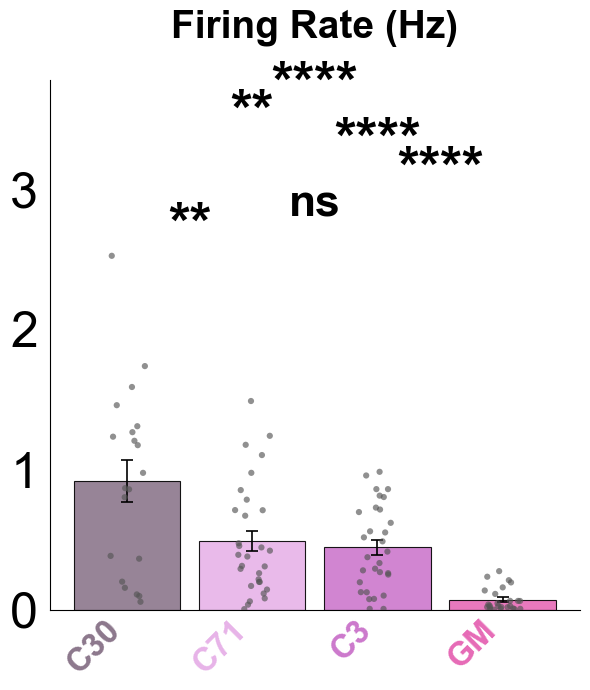

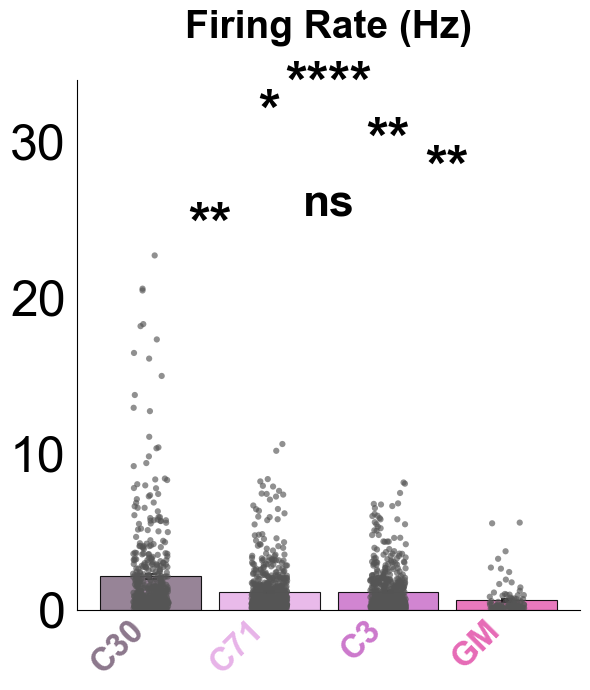


--- WELL-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 3.61e-06 ****
        age 2.04e-12 ****
group x age   0.0691   ns
Overall group differences (Holm):
group1 group2   diff    p-adj  sig
    C3    C30  0.243  0.00543   **
    C3    C71 0.0221    0.749   ns
    C3     GM -0.356  4.2e-06 ****
   C30    C71 -0.221  0.00914   **
   C30     GM -0.599 7.33e-13 ****
   C71     GM -0.379 1.08e-06 ****
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       **         ns       ***      ****
  7.6        ns        ns      ***         ns      ****      ****
  7.8        ns        ns      ***         ns      ****      ****
  8.0        ns        ns       ns          *      ****        ns
  8.5        **        ns       ns         **      ****        ns

--- ELECTRODE-LEVEL FIRING (BAR PLOT): mixed model, random interce

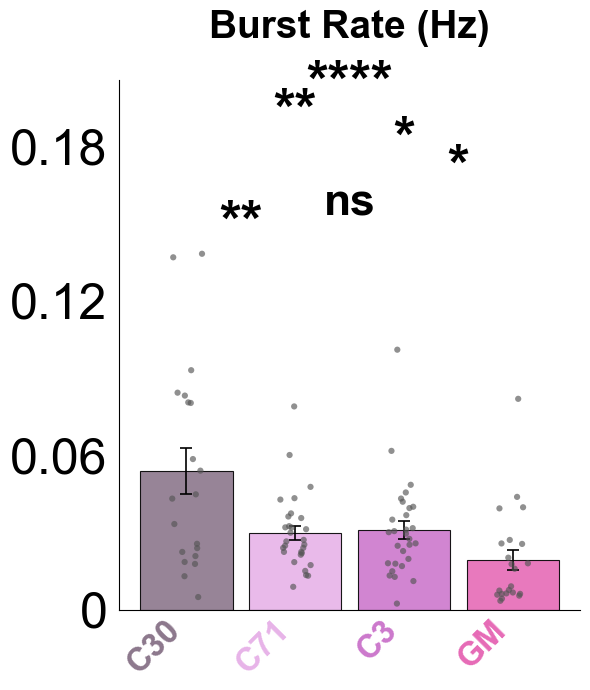

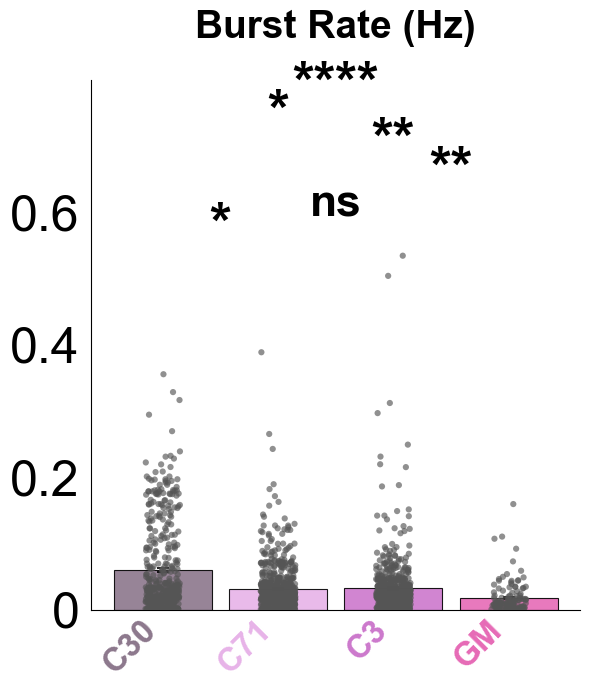


--- WELL-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=100, wells=21) ---
       term        p sig
      group 0.000256 ***
        age   0.0129   *
group x age   0.0149   *
Overall group differences (Holm):
group1 group2      diff    p-adj  sig
    C3    C30     0.046  0.00876   **
    C3    C71 -0.000864    0.949   ns
    C3     GM   -0.0413   0.0125    *
   C30    C71   -0.0468  0.00876   **
   C30     GM   -0.0873 1.85e-07 ****
   C71     GM   -0.0405   0.0125    *
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6         *        ns       ns         ns       ***        ns
  7.8        ns        ns       ns         ns        **        ns
  8.0        ns        ns       ns         ns        **        ns
  8.5        ns        ns       ns         ns       ***        ns

--- ELECTRODE-LEVEL BURST (BAR PLOT): mixed model,

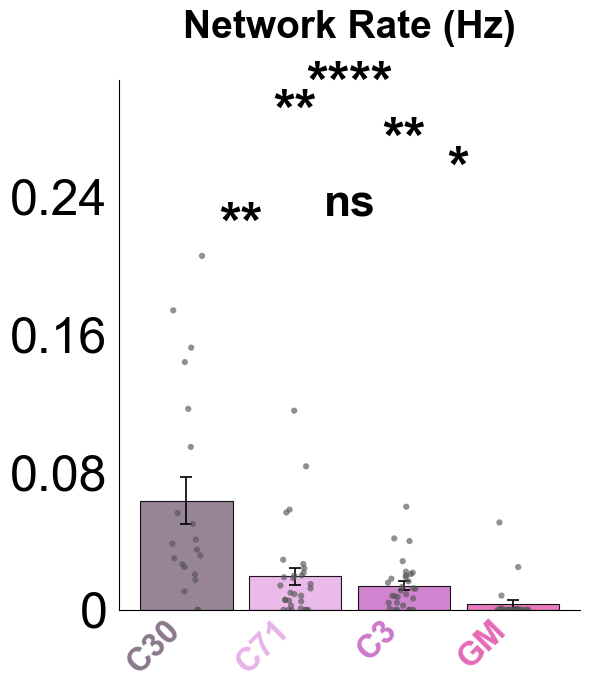


--- WELL-LEVEL NETWORK (BAR PLOT): mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 0.000131  ***
        age 7.97e-05 ****
group x age   0.0487    *
Overall group differences (Holm):
group1 group2    diff    p-adj  sig
    C3    C30   0.108  0.00201   **
    C3    C71 0.00977    0.719   ns
    C3     GM -0.0788   0.0118    *
   C30    C71 -0.0983  0.00515   **
   C30     GM  -0.187 2.26e-08 ****
   C71     GM -0.0886  0.00593   **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6         *        ns       ns          *      ****        ns
  7.8        ns        ns       ns         ns       ***        ns
  8.0        **        ns       ns          *      ****        ns
  8.5        **        ns       ns          *       ***        ns

--- GENERATING CLONE PLOTS FOR SYNCHRONY ---


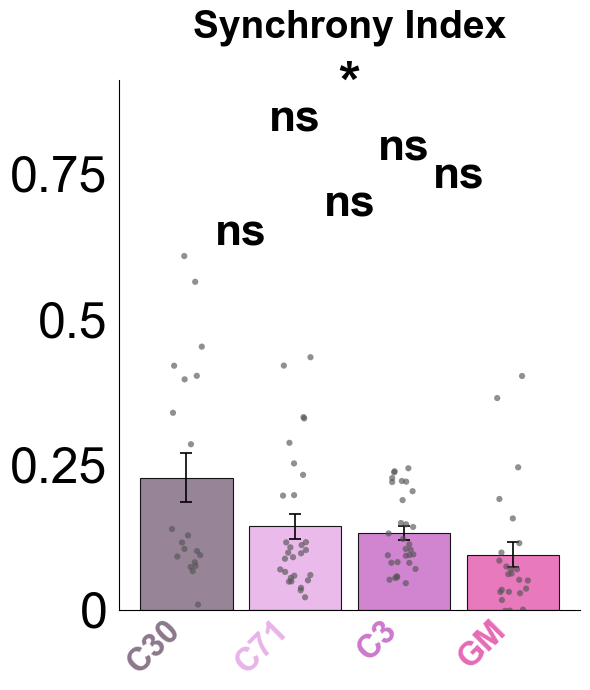


--- WELL-LEVEL SYNCHRONY (BAR PLOT): mixed model, random intercept per well (n=103, wells=21) ---
       term        p  sig
      group    0.102   ns
        age 9.99e-06 ****
group x age     0.56   ns
Overall group differences (Holm):
group1 group2    diff  p-adj sig
    C3    C30  0.0795  0.484  ns
    C3    C71  0.0116  0.786  ns
    C3     GM -0.0535  0.595  ns
   C30    C71 -0.0679  0.595  ns
   C30     GM  -0.133 0.0453   *
   C71     GM -0.0651  0.595  ns
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6        ns        ns       ns         ns        ns        ns
  7.8        ns        ns       ns         ns        ns        ns
  8.0        ns        ns       ns         ns        ns        ns
  8.5        ns        ns       ns         ns        ns        ns


In [14]:
# Bar plots by clone (replaces run_grouped_analysis)
run_grouped_analysis_by_clone(big_df, experiment="Exp3", save_dir=SUPP_SAVE_DIR)

# RASTER PLOTS

#### Find wells for rasterplots

In [15]:
# generate_activity_gallery(big_df, experiment="Exp3", num_options=20, duration=210)

#### Generate raster plots for figure

In [16]:
# def generate_final_raster(big_df, final_choices, duration=60, save_name="MAOA_Figure_Final.pdf"):
#     fig, axes = plt.subplots(3, 1, figsize=(4, 10), sharex=True)
#     groups = ["Xa:WT/Xi:MUT", "Xa:MUT/Xi:WT", "MAOA/B$^{-/Y}$"]
    
#     for ax, group in zip(axes, groups):
#         choice = final_choices[group]
#         # Search for the path in your big_df metadata
#         row = big_df[(big_df["plate_name"] == choice["plate"]) & 
#                       (big_df["well"] == choice["well"]) & 
#                       (big_df["experiment"] == "Exp3")].iloc[0]
        
#         # Load and clean spikes (applying the artifact filter one last time)
#         spikes = load_spike_list(row["spike_list_path"])
#         well_spikes = spikes[spikes["well"] == choice["well"]]
        
#         # Filter artifacts > 15Hz to keep it clean
#         t_tot = well_spikes["time_s"].max() - well_spikes["time_s"].min()
#         counts = well_spikes["electrode"].value_counts()
#         well_spikes = well_spikes[well_spikes["electrode"].isin(counts[counts / t_tot < 15].index)]
        
#         # Isolate window
#         w_spikes = well_spikes[(well_spikes["time_s"] >= choice["start_t"]) & 
#                                 (well_spikes["time_s"] < choice["start_t"] + duration)]
        
#         # Plotting
#         expected = [f"{choice['well']}_{r}{c}" for r in range(1, 9) for c in range(1, 9)]
#         trains = [w_spikes[w_spikes["electrode"] == e]["time_s"] - choice["start_t"] for e in expected]
        
#         ax.eventplot(trains, color='black', linelengths=0.9, linewidths=1.2)
        
#         # Styling
#         ax.set_title(group, color=MAOA_FIGURE_PALETTE[group], fontweight='bold', fontsize=22, pad=10)
#         ax.set_ylim(-1, 64)
#         ax.set_ylabel("Electrode Unit", fontsize=18)
#         ax.set_yticks([0, 31, 63])
#         ax.set_yticklabels([1, 32, 64], fontsize=14)

#     axes[-1].set_xlim(0, duration)
#     axes[-1].set_xlabel("Time (sec)", fontsize=16)
#     ax.set_xticks([0, 60, 120])
#     ax.set_xticklabels([0, 60, 120], fontsize=14)
#     sns.despine()
#     plt.tight_layout()
    
#     if save_name:
#         plt.savefig(save_name, bbox_inches='tight', transparent=True)
#         print(f"Figure saved successfully as {save_name}")
#     plt.show()

In [17]:
# raster_choices = {
#     "Xa:WT/Xi:MUT":   {"plate": "MAOA76", "well": "C2", "start_t": 1030}, 
#     "Xa:MUT/Xi:WT":   {"plate": "MAOA76", "well": "A2", "start_t":40},
#     "MAOA/B$^{-/Y}$": {"plate": "MAOA76", "well": "A4", "start_t": 55}
# }

In [18]:
# generate_final_raster(big_df, raster_choices, duration=120 )